# Six-method DeePC comparison on 1,000 paired Reacher seeds

This notebook compares **Select-DPC**, **Atlas-DeePC**, **Subspace Atlas-DeePC**, **Iterative-reference Atlas-DeePC**, **Contextual DPC**, and the finalized **Contextual Atlas-DeePC** on seeds 211--1210. Every method uses the same random-walk offline Hankel library, output map, offline goal-candidate eligibility rule, rank-60 representation, DeePC cost, constraints, solver, horizon, and environment seed.

The methods differ in chart centering, reference policy, and in how the behavioral matrix supplied to DeePC is selected or cached. Contextual DPC is included as a neutral comparator; the analysis does not visually emphasize it.

The first five methods' results are preserved. **Subspace Atlas-DeePC** uses an uncentered SVD with zero affine offset, retaining graph routing and all other baseline settings.

The added **Iterative-reference Atlas-DeePC** implements the user's candidate-route augmentation with **N=10**. It keeps the original affine charts, not the pure-subspace ablation. It reuses its completed 500-seed ablation and extends only this algorithm to seeds 711--1210.

## 1. Comparison contract

| Method | Behavioral matrix supplied to DeePC | Reference policy | Online data work |
|---|---|---|---|
| Select-DPC | Rank-60 SVD of the 200 L1-nearest complete Hankel columns | Atlas graph-routed waypoint | Scores all columns and rebuilds SVD every step |
| Atlas-DeePC | Cached rank-60 basis of the measured physical chart | Atlas graph-routed waypoint | Physical-chart localization and cached lookup |
| Subspace Atlas-DeePC | Cached rank-60 **uncentered** SVD of the same measured physical chart, $b=U_{k,60}g$ | Same Atlas graph-routed waypoint | Same physical-chart localization and cached lookup |
| Iterative-reference Atlas-DeePC | Same cached rank-60 affine basis as baseline Atlas | Repeatedly select the minimum-route-cost goal chart among the top-10 eligible near-target configurations, then follow graph waypoints | Cached shortest-path costs plus per-step candidate-chart selection |
| Contextual DPC | Rank-60 SVD of the 200 columns nearest in normalized $Y_p$ and $Q$-weighted $Y_f$ | Final graph-compatible goal from step 0 | Scores all columns and rebuilds SVD every step |
| Contextual Atlas-DeePC | Physical chart normally; after a causal stall, one cached rank-60 basis selected from 128 global $[Y_p,Q^{1/2}Y_f]$ prototypes | Atlas graph-routed waypoint and latched terminal goal | Scores 128 prototypes after triggering; no online column search or SVD |

Strict success uses the existing `success_30` and `success_100` flags: both final-30 and final-100 windows must have mean fingertip error below 1 cm and maximum error below 2 cm. No success labels were changed. All reported outcomes are paired by seed.

For the added method, each full-column chart matrix $H_k$ is factorized without mean subtraction. The first 60 left singular vectors are cached, and the affine offset is zero. The original empirical coefficient-bound rule and coefficient regularization are retained in the new coordinates. This is not the terminal-only ablation and not a contextual variant.

**Iterative augmentation:** gather the top-10 eligible offline configurations by fingertip distance once per rollout. At each step, choose the candidate chart with minimum directed route cost from the current chart; ties prefer smaller fingertip error, then source index. Use that candidate's posture with zero joint velocity and the requested fingertip target as the full terminal reference. Chart-to-chart shortest-path costs are precomputed offline; online rerouting uses the same graph costs as the candidate ablation. The 7 cm switch latches use of the terminal reference, but the candidate itself can still change online.

In [1]:
from pathlib import Path
import json
import math
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
if not (ROOT / 'src').exists():
    raise RuntimeError('Run this notebook from the atlas_deepc_reacher project root.')

SEEDS = list(range(211, 1211))
SOURCE_COMPARISON = ROOT / 'experiments/deepc_algorithm_comparison/six_way_svd_heldout111_1210_n200_rank60/summary.json'
CONTEXTUAL_ATLAS_FIRST = ROOT / 'experiments/routed_deepc_iid/contextual_cluster_eval211_710_global128_triggered/summary.json'
CONTEXTUAL_ATLAS_EXTENSION = ROOT / 'experiments/routed_deepc_iid/contextual_cluster_eval711_1210_global128_triggered/summary.json'
OUTPUT_DIR = ROOT / 'experiments/deepc_algorithm_comparison/six_method_with_iterative_reference_211_1210'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CONTROLLED_TIMING = (
    ROOT / 'experiments/deepc_algorithm_comparison'
    / 'four_method_controlled_serial_211_1210/summary.json'
)

required = [
    SOURCE_COMPARISON, CONTEXTUAL_ATLAS_FIRST, CONTEXTUAL_ATLAS_EXTENSION,
    CONTROLLED_TIMING,
]
assert all(path.exists() for path in required), [path for path in required if not path.exists()]
print(f'Paired evaluation panel: {SEEDS[0]}--{SEEDS[-1]} ({len(SEEDS)} seeds)')

NEW_METHOD = 'Subspace Atlas-DeePC'
SUBSPACE_DIR = ROOT / 'experiments/deepc_algorithm_comparison/subspace_atlas_serial_211_1210'
SUBSPACE_SUMMARY = SUBSPACE_DIR / 'summary.json'
RUN_NEW_METHOD = False

if RUN_NEW_METHOD:
    subprocess.run([
        sys.executable, 'src/subspace_comparison_experiment.py',
        '--seed-start', str(SEEDS[0]), '--seed-stop', str(SEEDS[-1]),
        '--output-dir', str(SUBSPACE_DIR),
    ], cwd=ROOT, check=True)
assert SUBSPACE_SUMMARY.exists(), 'Set RUN_NEW_METHOD=True to run only the new variant.'


ITERATIVE_METHOD = 'Iterative-reference Atlas-DeePC'
ITERATIVE_DIR = ROOT / 'experiments/deepc_algorithm_comparison/iterative_reference_n10_211_1210'
ITERATIVE_SUMMARY = ITERATIVE_DIR / 'summary.json'
RUN_ITERATIVE_METHOD = False
if RUN_ITERATIVE_METHOD:
    subprocess.run([
        sys.executable, 'src/iterative_reference_comparison.py',
        '--seed-start', str(SEEDS[0]), '--seed-stop', str(SEEDS[-1]),
        '--candidate-count', '10', '--output-dir', str(ITERATIVE_DIR),
    ], cwd=ROOT, check=True)
assert ITERATIVE_SUMMARY.exists(), 'Set RUN_ITERATIVE_METHOD=True to complete the new method.'


Paired evaluation panel: 211--1210 (1000 seeds)


## 2. Load and audit the paired rollouts

The first three methods are read from the completed 1,100-seed comparison and restricted to the requested 1,000-seed panel. Contextual Atlas-DeePC combines its original seeds 211--710 with the untouched extension 711--1210. No aggregate result is substituted for an individual rollout.

The pure-subspace variant has its own 1,000-seed result file. `RUN_NEW_METHOD=True` runs only that method and resumes compatible per-seed checkpoints. None of the four historical result or timing files is rewritten.

Iterative augmentation reuses the original N=10 rollout files for seeds 211--710 and adds new rollouts for 711--1210. **N=10 was chosen from the earlier 500-seed candidate-count ablation**, so the combined 1,000-seed result is not an untouched test. A separate 711--1210 result is reported below. No candidate count is tuned on that extension.

In [2]:
source = json.loads(SOURCE_COMPARISON.read_text())
contextual_first = json.loads(CONTEXTUAL_ATLAS_FIRST.read_text())
contextual_extension = json.loads(CONTEXTUAL_ATLAS_EXTENSION.read_text())

source_keys = {
    'Select-DPC': 'select_dpc_svd',
    'Atlas-DeePC': 'atlas',
    'Contextual DPC': 'contextual_final_svd',
}
results = {}
for label, key in source_keys.items():
    by_seed = {int(row['seed']): row for row in source['method_summaries'][key]}
    results[label] = [by_seed[seed] for seed in SEEDS]

contextual_rows = contextual_first['results'] + contextual_extension['results']
contextual_by_seed = {int(row['seed']): row for row in contextual_rows}
results['Contextual Atlas-DeePC'] = [contextual_by_seed[seed] for seed in SEEDS]

subspace_payload = json.loads(SUBSPACE_SUMMARY.read_text())
subspace_by_seed = {int(row['seed']): row for row in subspace_payload['results']}
results[NEW_METHOD] = [subspace_by_seed[seed] for seed in SEEDS]
iterative_payload = json.loads(ITERATIVE_SUMMARY.read_text())
iterative_by_seed = {int(row['seed']): row for row in iterative_payload['results']}
results[ITERATIVE_METHOD] = [iterative_by_seed[seed] for seed in SEEDS]
assert all(len(rows) == 1000 for rows in results.values())
assert all([int(row['seed']) for row in rows] == SEEDS for rows in results.values())

reference_config = dict(source['config'])
for payload in [contextual_first, contextual_extension]:
    candidate = dict(payload['config'])
    reference_config.pop('seed', None)
    candidate.pop('seed', None)
    assert candidate == reference_config
    cluster = payload['contextual_cluster']
    assert cluster['architecture'] == 'global_vq'
    assert cluster['contextual_clusters'] == 128
    assert cluster['support_columns'] == 200
    assert cluster['activation_mode'] == 'triggered'

assert {k: v for k, v in subspace_payload['config'].items() if k != 'seed'} == reference_config
assert subspace_payload['signature']['geometry'] == 'linear'
assert subspace_payload['signature']['reference_mode'] == 'graph'
assert all(a['data_goal_index'] == b['data_goal_index'] for a, b in zip(results['Atlas-DeePC'], results[NEW_METHOD]))

assert {k: v for k, v in iterative_payload['config'].items() if k != 'seed'} == reference_config
assert iterative_payload['candidate_count'] == 10
assert iterative_payload['signature']['geometry'] == 'affine'
assert all(row['dynamic_terminal_reference'] for row in results[ITERATIVE_METHOD])
assert all(row['minimum_selected_goal_source_separation'] >= 0.06 for row in results[ITERATIVE_METHOD])

all_rows = [row for rows in results.values() for row in rows]
assert all(row.get('fitted_dynamics_model') is False for row in all_rows)
assert all(row['data_goal_source_target_distance'] >= 0.06 for row in all_rows)
assert all(row['svd_rank'] == 60 for row in all_rows)
assert all(row['steps'] == 320 for row in all_rows)
assert all(row.get('online_svd_rebuild') is False for row in results['Contextual Atlas-DeePC'])
assert all(row.get('online_hankel_columns_scored') == 0 for row in results['Contextual Atlas-DeePC'])

display(pd.Series({
    'paired seed range': f'{SEEDS[0]}--{SEEDS[-1]}',
    'trials per method': len(SEEDS),
    'offline stabilized episodes': contextual_first['fairness_audit']['offline_stabilized_episode_count'],
    'minimum source-target separation': min(row['data_goal_source_target_distance'] for row in all_rows),
    'required source-target separation': 0.06,
    'fitted dynamics / IK feedback / fallback': 'none',
    'Contextual Atlas online full-column scores': 0,
    'Contextual Atlas online SVD rebuilds': 0,
}))

paired seed range                             211--1210
trials per method                                  1000
offline stabilized episodes                           0
minimum source-target separation               0.060162
required source-target separation                  0.06
fitted dynamics / IK feedback / fallback           none
Contextual Atlas online full-column scores            0
Contextual Atlas online SVD rebuilds                  0
dtype: object

## 3. Primary 1,000-seed result

The table uses the same strict sustained criterion for all methods. Confidence intervals are Wilson intervals for the binomial success proportion.

The four original computation measurements are retained from the completed serial benchmark. The new subspace method is measured in a **separate serial batch**, with the same timing boundary: one process, one numerical thread, 10 warm-up steps on seed 210 excluded, and the first five steps of each evaluated rollout discarded. Each entry is the median across rollout-level median control-step times. A timing difference between the new method and old methods may reflect machine conditions as well as algorithm changes; this is not a fresh interleaved five-method speed benchmark.


Iterative-reference timings combine its archived serial ablation and a new single-threaded serial extension. Both are summarized after dropping the first five control steps; the extension also excludes a 10-step warm-up. The archived rollout timings were not replaced. Treat timings across these batches as descriptive, not a controlled causal speed comparison.

In [3]:
METHOD_ORDER = ['Select-DPC', 'Atlas-DeePC', NEW_METHOD, ITERATIVE_METHOD, 'Contextual DPC', 'Contextual Atlas-DeePC']
controlled_payload = json.loads(CONTROLLED_TIMING.read_text())
controlled_aggregate = {
    row['method']: row for row in controlled_payload['aggregate']
}
controlled_aggregate.update({row['method']: row for row in subspace_payload['aggregate']})
controlled_aggregate.update({row['method']: row for row in iterative_payload['aggregate']})
controlled_records = pd.DataFrame(controlled_payload['per_seed'] + subspace_payload['per_seed'] + iterative_payload['per_seed'])
assert set(controlled_aggregate) == set(METHOD_ORDER)
assert len(controlled_records) == len(METHOD_ORDER) * len(SEEDS)
assert all(controlled_aggregate[method]['rollouts'] == len(SEEDS) for method in METHOD_ORDER)

def strict_success(row):
    return bool(row['success_30'] and row['success_100'])

def wilson(successes, trials, z=1.959963984540054):
    rate = successes / trials
    denominator = 1 + z*z/trials
    center = (rate + z*z/(2*trials)) / denominator
    half = z * np.sqrt(rate*(1-rate)/trials + z*z/(4*trials**2)) / denominator
    return center-half, center+half

def control_timing(row, statistic):
    current = f'{statistic}_control_compute_ms'
    legacy = f'{statistic}_control_compute_time_ms'
    return row[current] if current in row else row[legacy]

summary_rows = []
for method in METHOD_ORDER:
    rows = results[method]
    successes = sum(strict_success(row) for row in rows)
    low, high = wilson(successes, len(rows))
    summary_rows.append({
        'method': method,
        'successes': successes,
        'trials': len(rows),
        'success rate': successes / len(rows),
        'Wilson low': low,
        'Wilson high': high,
        'median final-100 (mm)': 1000*np.median([row['mean_last_100'] for row in rows]),
        'median prediction error (mm)': 1000*np.median([row['mean_prediction_error_xy'] for row in rows]),
        'median online compute (ms)': controlled_aggregate[method]['median total online control (ms)'],
        'p95 rollout-median compute (ms)': np.percentile(
            controlled_records.loc[
                controlled_records['method'] == method, 'total online control'
            ], 95,
        ),
    })

summary = pd.DataFrame(summary_rows).set_index('method')
display(summary.style.format({
    'success rate': '{:.1%}', 'Wilson low': '{:.1%}', 'Wilson high': '{:.1%}',
    'median final-100 (mm)': '{:.3f}', 'median prediction error (mm)': '{:.3f}',
    'median online compute (ms)': '{:.3f}', 'p95 rollout-median compute (ms)': '{:.3f}',
}))

,successes,trials,success rate,Wilson low,Wilson high,median final-100 (mm),median prediction error (mm),median online compute (ms),p95 rollout-median compute (ms)
method,,,,,,,,,
Select-DPC,715,1000,71.5%,68.6%,74.2%,3.593,2.703,59.451,88.736
Atlas-DeePC,883,1000,88.3%,86.2%,90.1%,2.116,1.721,34.776,49.205
Subspace Atlas-DeePC,892,1000,89.2%,87.1%,91.0%,2.032,1.644,32.581,35.318
Iterative-reference Atlas-DeePC,914,1000,91.4%,89.5%,93.0%,2.096,1.580,34.977,39.756
Contextual DPC,959,1000,95.9%,94.5%,97.0%,1.703,1.094,58.314,82.255
Contextual Atlas-DeePC,956,1000,95.6%,94.1%,96.7%,2.002,1.707,34.789,50.704


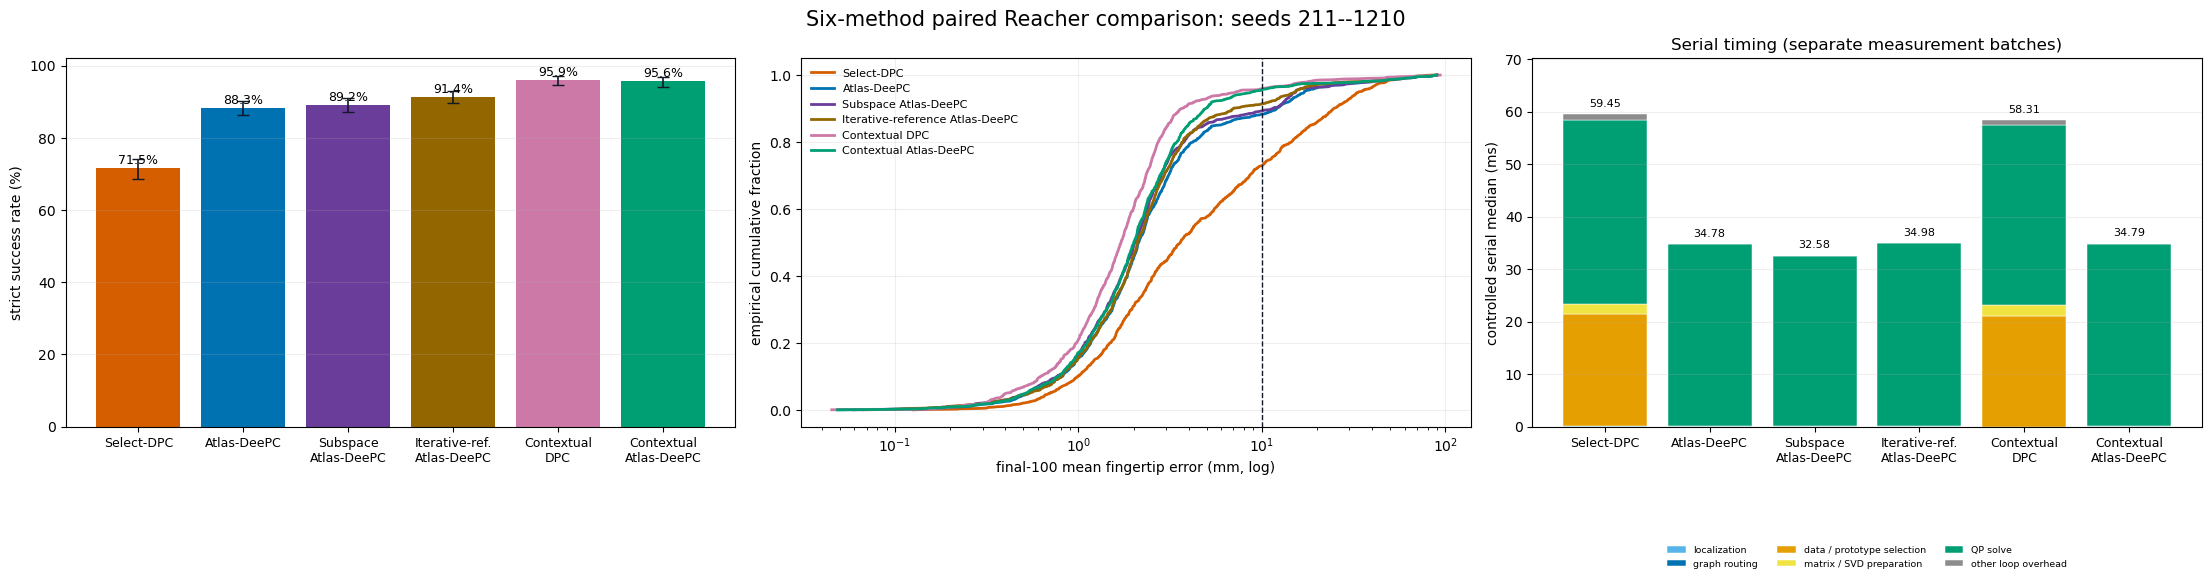

In [4]:
colors = {
    'Select-DPC': '#D55E00',
    'Atlas-DeePC': '#0072B2',
    NEW_METHOD: '#6A3D9A',
    ITERATIVE_METHOD: '#946600',
    'Contextual DPC': '#CC79A7',
    'Contextual Atlas-DeePC': '#009E73',
}

def stage_timing(row, stage):
    current = f'median_{stage}_ms'
    legacy = f'median_{stage}_time_ms'
    return float(row.get(current, row.get(legacy, 0.0)))

timing_rows = []
for method in METHOD_ORDER:
    measured = controlled_aggregate[method]
    components = {
        'localization': measured['median localization (ms)'],
        'graph routing': measured['median graph routing (ms)'],
        'data / prototype selection': measured['median data / prototype selection (ms)'],
        'matrix / SVD preparation': measured['median matrix / SVD preparation (ms)'],
        'QP solve': measured['median QP solve (ms)'],
    }
    total = float(summary.loc[method, 'median online compute (ms)'])
    components['other loop overhead'] = max(0.0, total - sum(components.values()))
    timing_rows.append({'method': method, **components, 'total': total})
timing_components = pd.DataFrame(timing_rows).set_index('method')

module_colors = {
    'localization': '#56B4E9',
    'graph routing': '#0072B2',
    'data / prototype selection': '#E69F00',
    'matrix / SVD preparation': '#F0E442',
    'QP solve': '#009E73',
    'other loop overhead': '#8C8C8C',
}
fig, axes = plt.subplots(1, 3, figsize=(22, 5.7), constrained_layout=True)

rates = summary.loc[METHOD_ORDER, 'success rate'].to_numpy()
lows = summary.loc[METHOD_ORDER, 'Wilson low'].to_numpy()
highs = summary.loc[METHOD_ORDER, 'Wilson high'].to_numpy()
x = np.arange(len(METHOD_ORDER))
axes[0].bar(x, 100*rates, color=[colors[m] for m in METHOD_ORDER])
axes[0].errorbar(x, 100*rates, yerr=[100*(rates-lows), 100*(highs-rates)],
                 fmt='none', ecolor='#111827', capsize=4, linewidth=1.2)
axes[0].set_ylim(0, 102)
axes[0].set_ylabel('strict success rate (%)')
for index, rate in enumerate(rates):
    axes[0].text(index, 100*rate+1.2, f'{100*rate:.1f}%', ha='center', fontsize=9)

for method in METHOD_ORDER:
    values = np.sort(1000*np.asarray([row['mean_last_100'] for row in results[method]]))
    axes[1].plot(values, np.arange(1, len(values)+1)/len(values),
                 color=colors[method], linewidth=2, label=method)
axes[1].axvline(10, color='#111827', linestyle='--', linewidth=1)
axes[1].set_xscale('log')
axes[1].set_xlabel('final-100 mean fingertip error (mm, log)')
axes[1].set_ylabel('empirical cumulative fraction')
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(alpha=0.2)

modules = list(module_colors)
bottom = np.zeros(len(METHOD_ORDER))
for module in modules:
    values = timing_components.loc[METHOD_ORDER, module].to_numpy()
    axes[2].bar(x, values, bottom=bottom, color=module_colors[module],
                label=module, edgecolor='white', linewidth=0.35)
    bottom += values
compute = timing_components.loc[METHOD_ORDER, 'total'].to_numpy()
axes[2].set_ylim(0, 1.18 * compute.max())
axes[2].set_ylabel('controlled serial median (ms)')
axes[2].set_title('Serial timing (separate measurement batches)')
for index, value in enumerate(compute):
    axes[2].text(index, value + 0.025*compute.max(), f'{value:.2f}',
                 ha='center', fontsize=8)
axes[2].legend(
    frameon=False, fontsize=6.8, ncol=3, loc='upper center',
    bbox_to_anchor=(0.5, -0.30),
)

short = ['Select-DPC', 'Atlas-DeePC', 'Subspace\nAtlas-DeePC', 'Iterative-ref.\nAtlas-DeePC', 'Contextual\nDPC', 'Contextual\nAtlas-DeePC']
for axis in [axes[0], axes[2]]:
    axis.set_xticks(x, short, rotation=0, ha='center', fontsize=9)
    axis.grid(axis='y', alpha=0.2)
fig.suptitle('Six-method paired Reacher comparison: seeds 211--1210', fontsize=15)
plot_path = OUTPUT_DIR / 'six_method_1000_seed_comparison.png'
fig.savefig(plot_path, dpi=170, bbox_inches='tight')
plt.show()

### Serial computation by module

Each entry is the median across 1,000 rollout-level median stage times. Matrix preparation includes online SVD for Select-DPC and Contextual DPC; all three Atlas variants use cached bases. The QP timing wraps controller problem construction, canonicalization, and solution, not only the solver's internal numerical iterations.

Medians of separate stages need not add exactly to the median total. The stacked chart is therefore a descriptive decomposition; its nonnegative residual is labeled **other loop overhead**.

The original four methods were interleaved in the original benchmark. Only the new subspace method ran in the added batch, with matching single-thread, warm-up, and discarded-step settings. Original measured values have not been replaced.


For iterative augmentation, the **data / prototype selection** column includes terminal-candidate chart selection (`goal_selection_time_s`); graph routing covers route reconstruction. One-time target-neighborhood construction is outside the control-step timing boundary and is shown separately below, rather than hidden in an online per-step speed claim.

,localization,graph routing,data / prototype selection,matrix / SVD preparation,QP solve,other loop overhead,total
method,,,,,,,
Select-DPC,0.053,0.005,21.406,1.876,35.093,1.019,59.451
Atlas-DeePC,0.060,0.005,0.000,0.001,34.658,0.053,34.776
Subspace Atlas-DeePC,0.064,0.005,0.000,0.001,32.453,0.059,32.581
Iterative-reference Atlas-DeePC,0.070,0.006,0.015,0.001,34.830,0.056,34.977
Contextual DPC,0.000,0.000,21.128,1.944,34.460,0.782,58.314
Contextual Atlas-DeePC,0.060,0.014,0.001,0.001,34.673,0.040,34.789


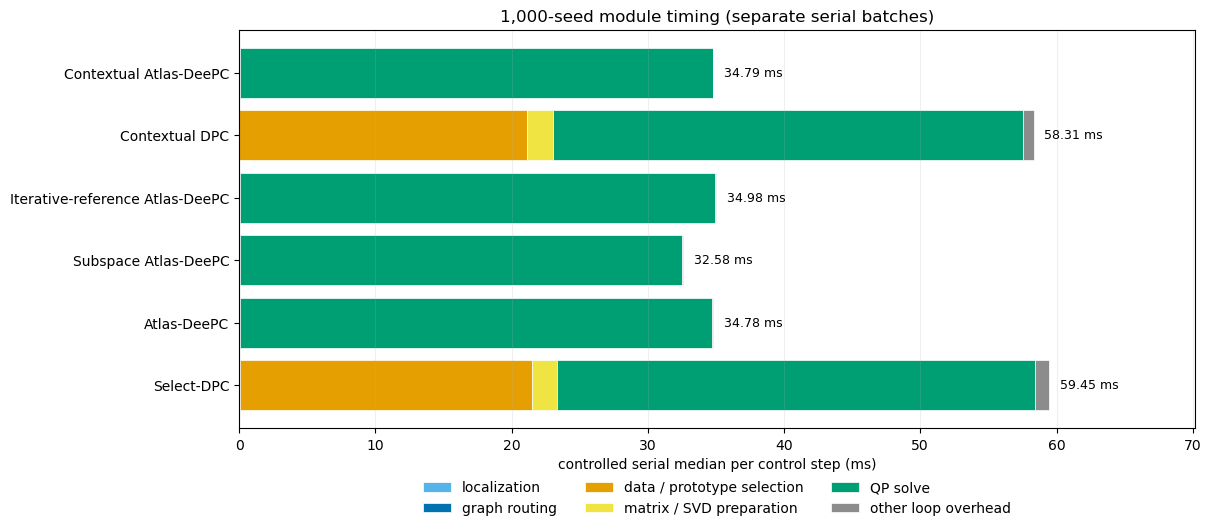

### Iterative augmentation: timing batches and one-time goal setup

,rollouts,median_step_ms,median_QP_ms,median_goal_selection_ms,median_route_ms,median_goal_setup_ms
timing_batch,,,,,,
archived candidate ablation,500,35.0605,34.9194,0.0148,0.0058,5.4511
new serial extension,500,34.6706,34.5573,0.0148,0.0061,5.0709


In [5]:
display(timing_components.style.format('{:.3f}'))

fig, ax = plt.subplots(figsize=(12, 5.2), constrained_layout=True)
left = np.zeros(len(METHOD_ORDER))
for module in modules:
    values = timing_components.loc[METHOD_ORDER, module].to_numpy()
    ax.barh(METHOD_ORDER, values, left=left, color=module_colors[module],
            label=module, edgecolor='white', linewidth=0.5)
    left += values
for index, total in enumerate(timing_components.loc[METHOD_ORDER, 'total']):
    ax.text(total + 0.8, index, f'{total:.2f} ms', va='center', fontsize=9)
ax.set_xlim(0, 1.18*timing_components['total'].max())
ax.set_xlabel('controlled serial median per control step (ms)')
ax.set_title('1,000-seed module timing (separate serial batches)')
ax.grid(axis='x', alpha=0.2)
ax.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.25))
timing_plot_path = OUTPUT_DIR / 'timing_module_breakdown_1000_seeds.png'
fig.savefig(timing_plot_path, dpi=170, bbox_inches='tight')
plt.show()

iterative_timing = controlled_records[controlled_records['method'] == ITERATIVE_METHOD]
timing_by_batch = iterative_timing.groupby('timing_batch').agg(
    rollouts=('seed', 'size'),
    median_step_ms=('total online control', 'median'),
    median_QP_ms=('QP solve', 'median'),
    median_goal_selection_ms=('data / prototype selection', 'median'),
    median_route_ms=('graph routing', 'median'),
    median_goal_setup_ms=('goal setup (ms)', 'median'),
)
display(Markdown('### Iterative augmentation: timing batches and one-time goal setup'))
display(timing_by_batch.style.format({c: '{:.4f}' for c in timing_by_batch if c != 'rollouts'}))


### Historical parallel-batch timing audit

The earlier multiprocessing batches reported an artificial Contextual Atlas QP gap. An untriggered Contextual Atlas rollout uses the same cached rank-60 physical-chart basis as Atlas-DeePC, and the fresh controlled benchmark above resolves the discrepancy. This audit is retained only to document why parallel-batch wall-clock timing was rejected.

In [6]:
atlas_by_seed = {int(row['seed']): row for row in results['Atlas-DeePC']}
contextual_atlas_by_seed = {
    int(row['seed']): row for row in results['Contextual Atlas-DeePC']
}

def qp_median(row):
    return stage_timing(row, 'solve')

def timing_audit_row(label, seeds):
    atlas_values = np.asarray([qp_median(atlas_by_seed[seed]) for seed in seeds])
    contextual_values = np.asarray([
        qp_median(contextual_atlas_by_seed[seed]) for seed in seeds
    ])
    return {
        'subset': label,
        'seeds': len(seeds),
        'Atlas QP median (ms)': np.median(atlas_values),
        'Contextual Atlas QP median (ms)': np.median(contextual_values),
        'median paired delta (ms)': np.median(contextual_values - atlas_values),
    }

triggered_seeds = [
    seed for seed in SEEDS if contextual_atlas_by_seed[seed]['contextual_triggered']
]
untriggered_seeds = sorted(set(SEEDS) - set(triggered_seeds))
timing_audit = pd.DataFrame([
    timing_audit_row('all seeds', SEEDS),
    timing_audit_row('untriggered', untriggered_seeds),
    timing_audit_row('triggered', triggered_seeds),
    timing_audit_row('first Contextual Atlas batch', list(range(211, 711))),
    timing_audit_row('second Contextual Atlas batch', list(range(711, 1211))),
]).set_index('subset')
display(timing_audit.style.format({
    'Atlas QP median (ms)': '{:.3f}',
    'Contextual Atlas QP median (ms)': '{:.3f}',
    'median paired delta (ms)': '{:+.3f}',
}))

display(Markdown(f'''The untriggered subset still shows a reported QP gap, while the two
Contextual Atlas batches show materially different QP medians under the same algorithm and
rank. This identifies batch load, process contention, scheduling, and machine state as the
dominant explanation. Triggered contextual bases may change numerical conditioning on the
{len(triggered_seeds)} triggered seeds, but they cannot explain the untriggered gap.'''))

,seeds,Atlas QP median (ms),Contextual Atlas QP median (ms),median paired delta (ms)
subset,,,,
all seeds,1000,40.847,56.456,+13.915
untriggered,875,40.536,56.229,+13.837
triggered,125,41.660,59.008,+15.613
first Contextual Atlas batch,500,45.144,51.823,+6.540
second Contextual Atlas batch,500,39.466,61.586,+22.225


The untriggered subset still shows a reported QP gap, while the two
Contextual Atlas batches show materially different QP medians under the same algorithm and
rank. This identifies batch load, process contention, scheduling, and machine state as the
dominant explanation. Triggered contextual bases may change numerical conditioning on the
125 triggered seeds, but they cannot explain the untriggered gap.

## 4. Paired statistical comparisons

McNemar's exact test uses only seeds on which a pair of methods disagree. The table reports how many successes are unique to Contextual Atlas-DeePC, how many successes are unique to the comparator, and the two-sided exact $p$-value. This is a paired diagnostic, not an independence test across methods.

A second paired table directly compares pure-subspace and affine Atlas-DeePC. These are exploratory, unadjusted comparisons; the first 500 seeds were already used in the preceding ablation.

In [7]:
def exact_mcnemar_p(first_only, second_only):
    discordant = first_only + second_only
    if discordant == 0:
        return 1.0
    smaller = min(first_only, second_only)
    tail = sum(math.comb(discordant, k) for k in range(smaller + 1))
    return min(1.0, 2.0 * tail / (2 ** discordant))

context_success = np.asarray([strict_success(row) for row in results['Contextual Atlas-DeePC']])
paired_rows = []
for comparator in METHOD_ORDER[:-1]:
    other = np.asarray([strict_success(row) for row in results[comparator]])
    contextual_only = int(np.sum(context_success & ~other))
    comparator_only = int(np.sum(~context_success & other))
    paired_rows.append({
        'comparator': comparator,
        'Contextual Atlas only': contextual_only,
        'comparator only': comparator_only,
        'net successes': contextual_only - comparator_only,
        'exact McNemar p': exact_mcnemar_p(contextual_only, comparator_only),
    })
display(pd.DataFrame(paired_rows).set_index('comparator').style.format({'exact McNemar p': '{:.4g}'}))

affine_success = np.asarray([strict_success(row) for row in results['Atlas-DeePC']])
subspace_success = np.asarray([strict_success(row) for row in results[NEW_METHOD]])
repaired = [seed for seed, a, b in zip(SEEDS, affine_success, subspace_success) if b and not a]
regressed = [seed for seed, a, b in zip(SEEDS, affine_success, subspace_success) if a and not b]
subspace_paired = {
    'subspace-only successes': len(repaired),
    'affine-only successes': len(regressed),
    'net repaired seeds': len(repaired) - len(regressed),
    'exact McNemar p': exact_mcnemar_p(len(repaired), len(regressed)),
    'repaired seeds': repaired,
    'regressed seeds': regressed,
}
display(Markdown('### Pure subspace versus affine Atlas-DeePC'))
display(pd.Series(subspace_paired))


iterative_success = np.asarray([strict_success(row) for row in results[ITERATIVE_METHOD]])
iterative_pairs = []
for panel, lo, hi in [('All comparison seeds (includes selection panel)', 211, 1210),
                      ('Prior candidate-count selection panel', 211, 710),
                      ('Extension after fixing N=10', 711, 1210)]:
    mask = (np.asarray(SEEDS) >= lo) & (np.asarray(SEEDS) <= hi)
    a, b = affine_success[mask], iterative_success[mask]
    gains, losses = int(np.sum(b & ~a)), int(np.sum(a & ~b))
    iterative_pairs.append({
        'panel': panel, 'seeds': int(mask.sum()),
        'affine successes': int(a.sum()), 'iterative successes': int(b.sum()),
        'repaired': gains, 'regressed': losses, 'net repaired': gains-losses,
        'exact McNemar p': exact_mcnemar_p(gains, losses),
    })
display(Markdown('### Iterative terminal augmentation versus fixed augmentation'))
display(pd.DataFrame(iterative_pairs).set_index('panel').style.format({'exact McNemar p': '{:.4g}'}))
display(pd.Series({
    'rollouts whose terminal sample changes online': sum(row['goal_sample_switches'] > 0 for row in results[ITERATIVE_METHOD]),
    'mean terminal sample switches per rollout': np.mean([row['goal_sample_switches'] for row in results[ITERATIVE_METHOD]]),
    'maximum terminal sample switches': max(row['goal_sample_switches'] for row in results[ITERATIVE_METHOD]),
}))


,Contextual Atlas only,comparator only,net successes,exact McNemar p
comparator,,,,
Select-DPC,258,17,241,1.76e-56
Atlas-DeePC,80,7,73,8.256e-17
Subspace Atlas-DeePC,74,10,64,3.286e-13
Iterative-reference Atlas-DeePC,65,23,42,8.501e-06
Contextual DPC,24,27,-3,0.7798


### Pure subspace versus affine Atlas-DeePC

subspace-only successes                                                   21
affine-only successes                                                     12
net repaired seeds                                                         9
exact McNemar p                                                     0.162756
repaired seeds             [254, 266, 283, 325, 343, 362, 445, 449, 526, ...
regressed seeds            [290, 296, 320, 326, 517, 548, 558, 611, 691, ...
dtype: object

### Iterative terminal augmentation versus fixed augmentation

,seeds,affine successes,iterative successes,repaired,regressed,net repaired,exact McNemar p
panel,,,,,,,
All comparison seeds (includes selection panel),1000,883,914,44,13,31,4.71e-05
Prior candidate-count selection panel,500,443,450,17,10,7,0.2478
Extension after fixing N=10,500,440,464,27,3,24,8.43e-06


rollouts whose terminal sample changes online     30.000
mean terminal sample switches per rollout          0.704
maximum terminal sample switches                 138.000
dtype: float64

## 5. Failure structure and contextual activation

The activation plot is specific to Contextual Atlas-DeePC. A zero fraction means the rollout completed entirely with the physical Atlas; a positive fraction is the portion of control steps after the terminal-stall trigger.

,failures,ever within 1 cm,ever within 2 cm,never within 2 cm
method,,,,
Select-DPC,285,173,243,42
Atlas-DeePC,117,34,88,29
Subspace Atlas-DeePC,108,18,78,30
Iterative-reference Atlas-DeePC,86,28,65,21
Contextual DPC,41,26,32,9
Contextual Atlas-DeePC,44,19,24,20


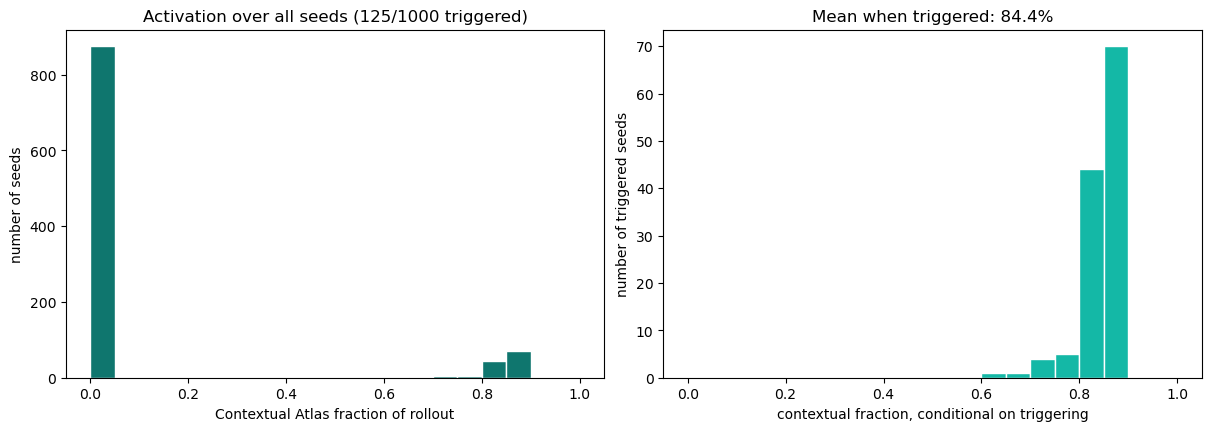

In [8]:
context_rows = results['Contextual Atlas-DeePC']
triggered = [row for row in context_rows if row['contextual_triggered']]
fractions = np.asarray([row['contextual_usage_fraction'] for row in context_rows])

failure_table = []
for method in METHOD_ORDER:
    failed = [row for row in results[method] if not strict_success(row)]
    failure_table.append({
        'method': method,
        'failures': len(failed),
        'ever within 1 cm': sum(row['minimum'] < 0.01 for row in failed),
        'ever within 2 cm': sum(row['minimum'] < 0.02 for row in failed),
        'never within 2 cm': sum(row['minimum'] >= 0.02 for row in failed),
    })
display(pd.DataFrame(failure_table).set_index('method'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].hist(fractions, bins=np.linspace(0, 1, 21), color='#0F766E', edgecolor='white')
axes[0].set_xlabel('Contextual Atlas fraction of rollout')
axes[0].set_ylabel('number of seeds')
axes[0].set_title(f'Activation over all seeds ({len(triggered)}/1000 triggered)')

triggered_fractions = fractions[fractions > 0]
axes[1].hist(triggered_fractions, bins=np.linspace(0, 1, 21), color='#14B8A6', edgecolor='white')
axes[1].set_xlabel('contextual fraction, conditional on triggering')
axes[1].set_ylabel('number of triggered seeds')
axes[1].set_title(f'Mean when triggered: {triggered_fractions.mean():.1%}')
activation_path = OUTPUT_DIR / 'contextual_atlas_activation_1000_seeds.png'
fig.savefig(activation_path, dpi=170, bbox_inches='tight')
plt.show()

## 6. Interpretation

This section is generated from the paired outcomes rather than from rounded aggregate rates.

In [9]:
contextual_dpc_success = int(summary.loc['Contextual DPC', 'successes'])
contextual_atlas_success = int(summary.loc['Contextual Atlas-DeePC', 'successes'])
comparison_row = next(row for row in paired_rows if row['comparator'] == 'Contextual DPC')
atlas_time = summary.loc['Atlas-DeePC', 'median online compute (ms)']
select_time = summary.loc['Select-DPC', 'median online compute (ms)']
contextual_dpc_time = summary.loc['Contextual DPC', 'median online compute (ms)']
contextual_atlas_time = summary.loc['Contextual Atlas-DeePC', 'median online compute (ms)']
display(Markdown(f'''
Contextual Atlas-DeePC succeeds on **{contextual_atlas_success}/1000** seeds, compared with
**{contextual_dpc_success}/1000** for final-reference Contextual DPC. Their net difference is
{contextual_atlas_success-contextual_dpc_success:+d} seeds, with paired exact McNemar
$p={comparison_row['exact McNemar p']:.3f}$; this panel does not establish a success-rate
difference between them.

Contextual Atlas-DeePC scores no full Hankel columns and rebuilds no SVD online. It triggers on
**{len(triggered)}/1000** rollouts; the remaining {1000-len(triggered)} rollouts use only the
physical Atlas basis. In the retained four-method controlled benchmark it requires **{contextual_atlas_time:.2f}
ms** per control step, numerically very close from physical
Atlas-DeePC's **{atlas_time:.2f} ms**. Cached Atlas control is **{1-atlas_time/select_time:.1%}
faster** than Select-DPC, while Contextual Atlas is **{1-contextual_atlas_time/contextual_dpc_time:.1%}
faster** than full online Contextual DPC.
'''))

display(Markdown(f'''
### Added pure-subspace variant
**Subspace Atlas-DeePC: {int(summary.loc[NEW_METHOD, 'successes'])}/{len(SEEDS)}**, versus
**{int(summary.loc['Atlas-DeePC', 'successes'])}/{len(SEEDS)}** for affine Atlas-DeePC.
It repairs {len(repaired)} seeds and regresses {len(regressed)}; the exploratory paired
McNemar p-value is **{subspace_paired['exact McNemar p']:.4g}**.

Its separately measured median online time is **{summary.loc[NEW_METHOD, 'median online compute (ms)']:.2f} ms**
per step, including **{controlled_aggregate[NEW_METHOD]['median QP solve (ms)']:.2f} ms**
inside the controller solve call. The four previous timing rows are unchanged.
The new-versus-old timing difference should not be attributed solely to removing the affine offset.
'''))


iterative_all, _, iterative_extension = iterative_pairs
display(Markdown(f'''
### User-proposed iterative terminal augmentation (N=10)
Iterative-reference Atlas-DeePC succeeds on **{iterative_all['iterative successes']}/1000**
seeds versus **{iterative_all['affine successes']}/1000** for the original fixed augmentation.
It repairs **{iterative_all['repaired']}** seeds and regresses **{iterative_all['regressed']}**
(exploratory paired p={iterative_all['exact McNemar p']:.4g}).

N=10 was selected using the earlier seeds 211--710. On the separate extension 711--1210,
the counts are **{iterative_extension['iterative successes']}/500** versus
**{iterative_extension['affine successes']}/500** (paired p={iterative_extension['exact McNemar p']:.4g}).
Only terminal augmentation and its route lookup change; this method retains the original affine
chart matrices, QP, offline data, and source-target separation rule. It does not use contextual rescue.
'''))



Contextual Atlas-DeePC succeeds on **956/1000** seeds, compared with
**959/1000** for final-reference Contextual DPC. Their net difference is
-3 seeds, with paired exact McNemar
$p=0.780$; this panel does not establish a success-rate
difference between them.

Contextual Atlas-DeePC scores no full Hankel columns and rebuilds no SVD online. It triggers on
**125/1000** rollouts; the remaining 875 rollouts use only the
physical Atlas basis. In the retained four-method controlled benchmark it requires **34.79
ms** per control step, numerically very close from physical
Atlas-DeePC's **34.78 ms**. Cached Atlas control is **41.5%
faster** than Select-DPC, while Contextual Atlas is **40.3%
faster** than full online Contextual DPC.



### Added pure-subspace variant
**Subspace Atlas-DeePC: 892/1000**, versus
**883/1000** for affine Atlas-DeePC.
It repairs 21 seeds and regresses 12; the exploratory paired
McNemar p-value is **0.1628**.

Its separately measured median online time is **32.58 ms**
per step, including **32.45 ms**
inside the controller solve call. The four previous timing rows are unchanged.
The new-versus-old timing difference should not be attributed solely to removing the affine offset.



### User-proposed iterative terminal augmentation (N=10)
Iterative-reference Atlas-DeePC succeeds on **914/1000**
seeds versus **883/1000** for the original fixed augmentation.
It repairs **44** seeds and regresses **13**
(exploratory paired p=4.71e-05).

N=10 was selected using the earlier seeds 211--710. On the separate extension 711--1210,
the counts are **464/500** versus
**440/500** (paired p=8.43e-06).
Only terminal augmentation and its route lookup change; this method retains the original affine
chart matrices, QP, offline data, and source-target separation rule. It does not use contextual rescue.


## 7. Save the compact comparison record

The full rollout files remain in their original experiment directories. This notebook writes only a compact per-seed comparison record and the aggregate table, avoiding another copy of the numerical trajectories.

In [10]:
compact = {
    'seed_range': [SEEDS[0], SEEDS[-1]],
    'trials_per_method': len(SEEDS),
    'strict_success_definition': 'both final-30 and final-100: mean error < 0.01 m and max error < 0.02 m',
    'iterative_paired': iterative_pairs,
    'iterative_selection_caveat': iterative_payload['protocol']['selection_caveat'],
    'iterative_timing_caveat': iterative_payload['protocol']['timing_caveat'],
    'subspace_paired': subspace_paired,
    'timing_caveat': subspace_payload['protocol']['timing_caveat'],
    'methods': summary.reset_index().to_dict(orient='records'),
    'per_seed': {
        method: [{
            'seed': int(row['seed']),
            'success': strict_success(row),
            'mean_last_30': float(row['mean_last_30']),
            'mean_last_100': float(row['mean_last_100']),
            'minimum': float(row['minimum']),
            'median_control_compute_ms': float(
                controlled_records.loc[
                    (controlled_records['method'] == method)
                    & (controlled_records['seed'] == int(row['seed'])),
                    'total online control',
                ].iloc[0]
            ),
        } for row in results[method]]
        for method in METHOD_ORDER
    },
    'sources': {
        'iterative_reference': str(ITERATIVE_SUMMARY),
        'subspace_atlas': str(SUBSPACE_SUMMARY),
        'original_controlled_timing': str(CONTROLLED_TIMING),
        'three_comparators': str(SOURCE_COMPARISON),
        'contextual_atlas_211_710': str(CONTEXTUAL_ATLAS_FIRST),
        'contextual_atlas_711_1210': str(CONTEXTUAL_ATLAS_EXTENSION),
    },
}
compact_path = OUTPUT_DIR / 'summary.json'
compact_path.write_text(json.dumps(compact, indent=2))
print('Saved:', compact_path)

Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/deepc_algorithm_comparison/six_method_with_iterative_reference_211_1210/summary.json


## 8. Result and timing provenance

The original four-method notebook is archived beside its original compact results. This notebook writes its five-method record and plots into a new directory. To run only the new variant, enable `RUN_NEW_METHOD` in the setup cell; compatible completed seeds are reused. For a fresh local timing measurement, choose a new `SUBSPACE_DIR` before running. None of these controls launches the four historical methods.


The five-method notebook is also archived. `RUN_ITERATIVE_METHOD=True` reuses compatible archived candidate experiments and runs missing iterative-reference seeds only. It does not run any other method. The original candidate ablation files remain unchanged.

In [11]:
display(pd.DataFrame([
    {'methods': 'Original four methods',
     'timestamp UTC': controlled_payload['protocol']['timestamp_utc'],
     'source': str(CONTROLLED_TIMING), 'rerun in this update': False},
    {'methods': NEW_METHOD,
     'timestamp UTC': subspace_payload['protocol']['timestamp_utc'],
     'source': str(SUBSPACE_SUMMARY), 'rerun in this update': False},
    {'methods': ITERATIVE_METHOD,
     'timestamp UTC': iterative_payload['protocol']['timestamp_utc'],
     'source': str(ITERATIVE_SUMMARY), 'rerun in this update': 'Only 500 missing seeds'},
]))
print('Original four-method notebook:',
      ROOT / 'experiments/deepc_algorithm_comparison/four_method_contextual_atlas_211_1210/comparison_before_subspace.ipynb')


,methods,timestamp UTC,source,rerun in this update
0,Original four methods,2026-08-29T00:51:53.520640+00:00,/Users/kumiko/Projects/atlas_deepc_reacher/exp...,False
1,Subspace Atlas-DeePC,2026-09-07T04:50:44.691713+00:00,/Users/kumiko/Projects/atlas_deepc_reacher/exp...,False
2,Iterative-reference Atlas-DeePC,2026-09-07T20:49:51.680260+00:00,/Users/kumiko/Projects/atlas_deepc_reacher/exp...,Only 500 missing seeds


Original four-method notebook: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/deepc_algorithm_comparison/four_method_contextual_atlas_211_1210/comparison_before_subspace.ipynb
